# 🔐 Cipher Classifier — Модуль 2: Признаки и классификатор

В этом ноутбуке мы:
1. Загружаем датасет из Модуля 1
2. Извлекаем математические признаки из каждого текста
3. Обучаем классификатор Random Forest
4. Оцениваем качество и смотрим какие признаки важнее всего

## 📦 Импорты

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import string
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder

print('✅ Все библиотеки загружены')

✅ Все библиотеки загружены


## 📂 Загрузка датасета

In [2]:
df = pd.read_csv('cipher_dataset.csv')

print(f'Загружено строк: {len(df)}')
print(f'Классов: {df["label"].nunique()}')
print(f'\nРаспределение:')
print(df['label'].value_counts())

Загружено строк: 2100
Классов: 7

Распределение:
label
rail_fence    300
plaintext     300
atbash        300
vigenere      300
bacon         300
caesar        300
playfair      300
Name: count, dtype: int64


## 🧮 Извлечение признаков

Для каждого зашифрованного текста вычислим набор математических характеристик.
Именно эти числа подадим в классификатор вместо сырого текста.

### Признак 1: Частоты 26 букв
Базовый признак — насколько часто встречается каждая буква.

$$f_i = \frac{\text{count}(\text{буква}_i)}{\text{длина текста}}, \quad i = A, B, \ldots, Z$$

In [3]:
def letter_frequencies(text: str) -> list:
    """26 признаков: относительная частота каждой буквы"""
    text = ''.join(c for c in text.upper() if c.isalpha())
    total = len(text) if len(text) > 0 else 1
    return [text.count(chr(ord('A') + i)) / total for i in range(26)]

# Тест
example = 'KHOOR'  # "HELLO" зашифрованное Цезарем со сдвигом 3
freq = letter_frequencies(example)
print('Частоты для "KHOOR":')
for i, f in enumerate(freq):
    if f > 0:
        print(f'  {chr(ord("A") + i)}: {f:.2f}')

Частоты для "KHOOR":
  H: 0.20
  K: 0.20
  O: 0.40
  R: 0.20


### Признак 2: Индекс совпадений (Index of Coincidence)

Вероятность того, что две случайно выбранные буквы текста одинаковы:

$$IC = \frac{\sum_{i=A}^{Z} n_i(n_i - 1)}{N(N-1)}$$

где $n_i$ — количество буквы $i$, $N$ — длина текста.

| Текст | IC ≈ |
|---|---|
| Английский plaintext | 0.065 |
| Цезарь | 0.065 (сдвиг не меняет IC!) |
| Виженер | 0.045 (более равномерный) |
| Случайный текст | 0.038 |
| Бэкон | ~0.500 (только A и B) |

In [4]:
def index_of_coincidence(text: str) -> float:
    """Индекс совпадений — ключевой признак для различия моноалфавитных и полиалфавитных шифров"""
    text = ''.join(c for c in text.upper() if c.isalpha())
    N = len(text)
    if N < 2:
        return 0.0
    counts = [text.count(chr(ord('A') + i)) for i in range(26)]
    return sum(n * (n - 1) for n in counts) / (N * (N - 1))

# Демонстрация
samples = {
    'plaintext': 'MATHEMATICSISTHELANGUAGEINWHICHGODHASWRITTENTHEUNIVERSE',
    'caesar':    'PDWKHPDWLFVLVWKHODQJXDJHLQZKLFKJRGKDVZULWWHQWKHXQLYHUVH',
    'vigenere':  'OCVLIQOCVKEUKULVJGNCPIWCIGKPYJKEJIQFJCUXTKVVGPVJGWPKXGTUG',
    'bacon':     'AAAABABAABABAAAABABAABABAABABB',
}

print('Индекс совпадений для разных шифров:')
for label, text in samples.items():
    ic = index_of_coincidence(text)
    print(f'  {label:12s}: IC = {ic:.4f}')

Индекс совпадений для разных шифров:
  plaintext   : IC = 0.0646
  caesar      : IC = 0.0646
  vigenere    : IC = 0.0564
  bacon       : IC = 0.5195


### Признак 3: Энтропия Шеннона

Мера «случайности» текста. Чем равномернее распределение букв — тем выше энтропия:

$$H = -\sum_{i=A}^{Z} p_i \log_2 p_i$$

Максимум при равномерном распределении: $H_{max} = \log_2 26 \approx 4.7$ бит.

In [5]:
def shannon_entropy(text: str) -> float:
    """Энтропия Шеннона в битах"""
    text = ''.join(c for c in text.upper() if c.isalpha())
    total = len(text)
    if total == 0:
        return 0.0
    probs = [text.count(chr(ord('A') + i)) / total for i in range(26)]
    return -sum(p * np.log2(p) for p in probs if p > 0)

print('Энтропия Шеннона для разных шифров:')
for label, text in samples.items():
    h = shannon_entropy(text)
    print(f'  {label:12s}: H = {h:.4f} бит')
print(f'  Теоретический максимум: H_max = {np.log2(26):.4f} бит')

Энтропия Шеннона для разных шифров:
  plaintext   : H = 3.8078 бит
  caesar      : H = 3.8078 бит
  vigenere    : H = 3.9426 бит
  bacon       : H = 0.9481 бит
  Теоретический максимум: H_max = 4.7004 бит


### Признак 4: Количество уникальных букв

Простой, но мощный признак — особенно для шифра Бэкона (всегда 2).

In [6]:
def unique_letters(text: str) -> int:
    """Количество уникальных букв в тексте"""
    return len(set(c for c in text.upper() if c.isalpha()))

print('Уникальных букв:')
for label, text in samples.items():
    print(f'  {label:12s}: {unique_letters(text)}')

Уникальных букв:
  plaintext   : 17
  caesar      : 17
  vigenere    : 18
  bacon       : 2


### Признак 5: Доля частых биграмм

Биграмма — пара соседних букв. В английском тексте есть типичные биграммы (TH, HE, IN, ER...).
После шифрования их распределение меняется характерным образом.

In [7]:
# Топ-10 биграмм английского языка
COMMON_BIGRAMS = ['TH','HE','IN','ER','AN','RE','ON','EN','AT','OU']

def bigram_features(text: str) -> list:
    """
    10 признаков: частота каждой из топ-10 биграмм английского языка.
    Помогает отличить plaintext и Цезарь от остальных шифров.
    """
    text = ''.join(c for c in text.upper() if c.isalpha())
    total_bigrams = len(text) - 1
    if total_bigrams <= 0:
        return [0.0] * len(COMMON_BIGRAMS)
    bigrams_in_text = [text[i:i+2] for i in range(total_bigrams)]
    return [bigrams_in_text.count(bg) / total_bigrams for bg in COMMON_BIGRAMS]

print('Частоты биграммы TH в разных шифрах:')
for label, text in samples.items():
    bg = bigram_features(text)
    print(f'  {label:12s}: TH = {bg[0]:.4f}')

Частоты биграммы TH в разных шифрах:
  plaintext   : TH = 0.0556
  caesar      : TH = 0.0000
  vigenere    : TH = 0.0000
  bacon       : TH = 0.0000


### Признак 6: Доля совпадающих диграмм (для Плейфера)

Плейфер никогда не шифрует одинаковые буквы подряд (вставляет X между ними).
Значит в зашифрованном тексте **не будет удвоенных букв** (AA, BB, CC...).

In [8]:
def double_letter_ratio(text: str) -> float:
    """Доля удвоенных пар букв (XX, AA, BB...). У Плейфера = 0."""
    text = ''.join(c for c in text.upper() if c.isalpha())
    if len(text) < 2:
        return 0.0
    doubles = sum(1 for i in range(len(text) - 1) if text[i] == text[i+1])
    return doubles / (len(text) - 1)

print('Доля удвоенных букв:')
for label, text in samples.items():
    print(f'  {label:12s}: {double_letter_ratio(text):.4f}')

Доля удвоенных букв:
  plaintext   : 0.0185
  caesar      : 0.0185
  vigenere    : 0.0179
  bacon       : 0.3448


## 🏗️ Сборка финального вектора признаков

Итого признаков на один текст:
- 26 (частоты букв) + 1 (IC) + 1 (энтропия) + 1 (уникальные буквы) + 10 (биграммы) + 1 (удвоения) = **40 признаков**

In [9]:
def extract_features(text: str) -> list:
    """Извлекает все 40 признаков из текста"""
    return (
        letter_frequencies(text) +          # 26 признаков
        [index_of_coincidence(text)] +       # 1
        [shannon_entropy(text)] +            # 1
        [unique_letters(text)] +             # 1
        bigram_features(text) +              # 10
        [double_letter_ratio(text)]          # 1
    )  # итого: 40

# Названия признаков (для интерпретации)
FEATURE_NAMES = (
    [f'freq_{c}' for c in string.ascii_uppercase] +
    ['index_of_coincidence', 'shannon_entropy', 'unique_letters'] +
    [f'bigram_{bg}' for bg in COMMON_BIGRAMS] +
    ['double_letter_ratio']
)

print(f'Признаков всего: {len(FEATURE_NAMES)}')
print(f'Список: {FEATURE_NAMES}')

Признаков всего: 40
Список: ['freq_A', 'freq_B', 'freq_C', 'freq_D', 'freq_E', 'freq_F', 'freq_G', 'freq_H', 'freq_I', 'freq_J', 'freq_K', 'freq_L', 'freq_M', 'freq_N', 'freq_O', 'freq_P', 'freq_Q', 'freq_R', 'freq_S', 'freq_T', 'freq_U', 'freq_V', 'freq_W', 'freq_X', 'freq_Y', 'freq_Z', 'index_of_coincidence', 'shannon_entropy', 'unique_letters', 'bigram_TH', 'bigram_HE', 'bigram_IN', 'bigram_ER', 'bigram_AN', 'bigram_RE', 'bigram_ON', 'bigram_EN', 'bigram_AT', 'bigram_OU', 'double_letter_ratio']


In [10]:
# Применяем ко всему датасету
print('Извлекаем признаки...')
X = np.array([extract_features(text) for text in df['ciphertext']])
y = df['label'].values

print(f'✅ Матрица признаков: {X.shape}  ({X.shape[0]} примеров × {X.shape[1]} признаков)')
print(f'   Метки: {np.unique(y)}')

Извлекаем признаки...
✅ Матрица признаков: (2100, 40)  (2100 примеров × 40 признаков)
   Метки: ['atbash' 'bacon' 'caesar' 'plaintext' 'playfair' 'rail_fence' 'vigenere']


## ✂️ Разбивка на train/test

80% данных — для обучения, 20% — для проверки качества на новых примерах.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Train: {X_train.shape[0]} примеров')
print(f'Test:  {X_test.shape[0]} примеров')

Train: 1680 примеров
Test:  420 примеров


## 🌲 Обучение Random Forest

Random Forest — ансамбль деревьев решений. Каждое дерево обучается на случайном подмножестве данных и признаков, итоговый ответ — голосование.

Почему Random Forest?
- Хорошо работает на небольших датасетах
- Не требует нормализации признаков
- Даёт интерпретируемый результат: важность каждого признака
- Устойчив к выбросам

In [12]:
model = RandomForestClassifier(
    n_estimators=200,    # количество деревьев
    max_depth=None,      # деревья растут до полного разделения
    random_state=42,
    n_jobs=-1            # использовать все ядра процессора
)

model.fit(X_train, y_train)
print('✅ Модель обучена!')

✅ Модель обучена!


## 📊 Оценка качества

In [13]:
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f'Точность на тестовой выборке: {acc:.4f} ({acc*100:.1f}%)')
print()
print('Детальный отчёт по классам:')
print(classification_report(y_test, y_pred))

Точность на тестовой выборке: 0.9167 (91.7%)

Детальный отчёт по классам:
              precision    recall  f1-score   support

      atbash       0.95      1.00      0.98        60
       bacon       1.00      1.00      1.00        60
      caesar       0.89      0.90      0.89        60
   plaintext       0.95      0.98      0.97        60
    playfair       0.78      0.90      0.84        60
  rail_fence       0.97      0.95      0.96        60
    vigenere       0.89      0.68      0.77        60

    accuracy                           0.92       420
   macro avg       0.92      0.92      0.91       420
weighted avg       0.92      0.92      0.91       420



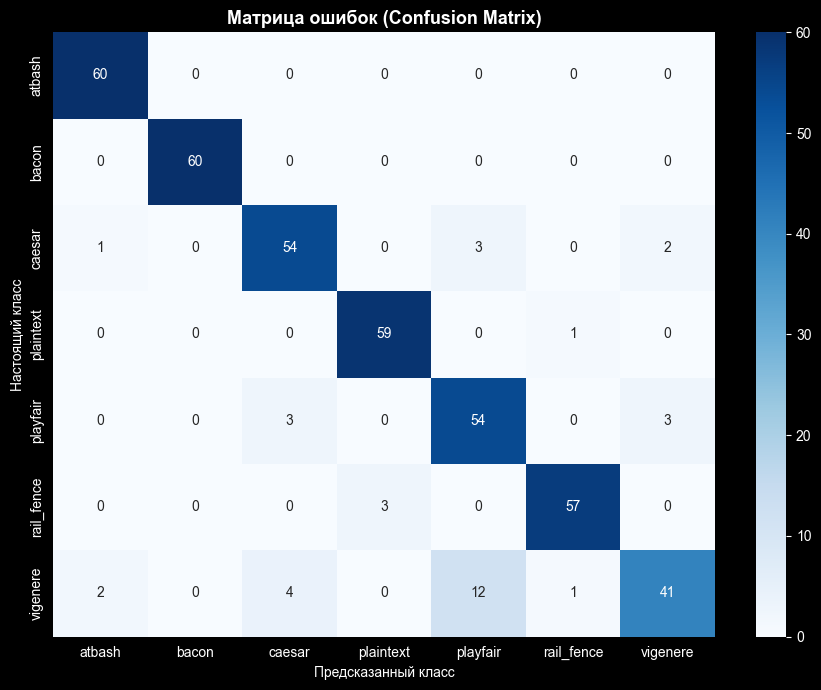

💡 Диагональ — правильные предсказания. Всё остальное — ошибки.


In [14]:
# Матрица ошибок
classes = sorted(np.unique(y))
cm = confusion_matrix(y_test, y_pred, labels=classes)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=classes, yticklabels=classes
)
plt.title('Матрица ошибок (Confusion Matrix)', fontsize=13, fontweight='bold')
plt.ylabel('Настоящий класс')
plt.xlabel('Предсказанный класс')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('💡 Диагональ — правильные предсказания. Всё остальное — ошибки.')

## 🔍 Важность признаков

Random Forest умеет показывать, какие признаки сильнее всего влияли на решение.

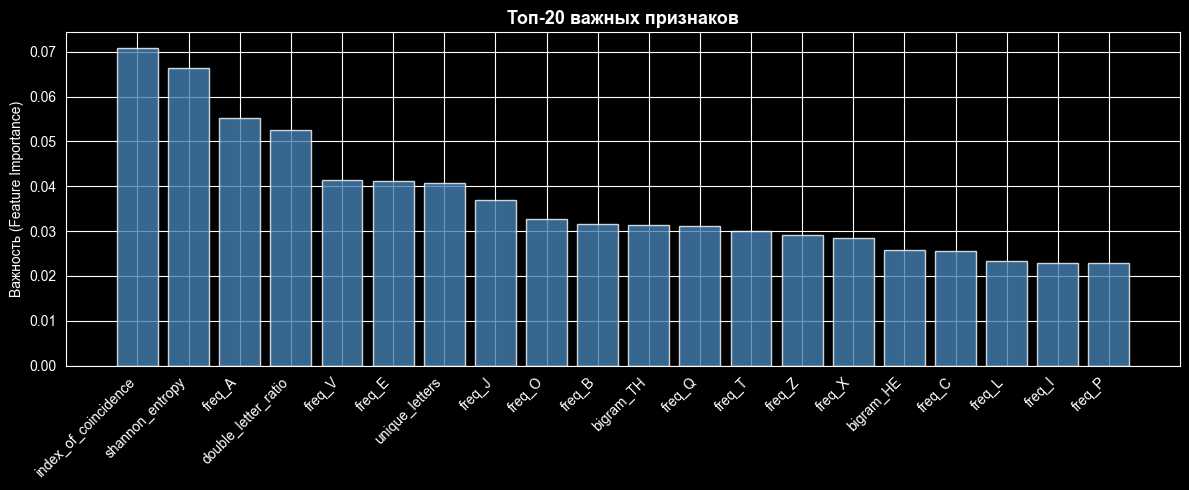

Топ-5 признаков:
  index_of_coincidence          : 0.0708
  shannon_entropy               : 0.0664
  freq_A                        : 0.0552
  double_letter_ratio           : 0.0526
  freq_V                        : 0.0415


In [15]:
importances = model.feature_importances_
indices = np.argsort(importances)[::-1][:20]  # топ-20

plt.figure(figsize=(12, 5))
plt.bar(range(20), importances[indices], color='steelblue', alpha=0.8)
plt.xticks(range(20), [FEATURE_NAMES[i] for i in indices], rotation=45, ha='right')
plt.title('Топ-20 важных признаков', fontsize=13, fontweight='bold')
plt.ylabel('Важность (Feature Importance)')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print('Топ-5 признаков:')
for i in indices[:5]:
    print(f'  {FEATURE_NAMES[i]:30s}: {importances[i]:.4f}')

## 🧪 Тест на новом тексте

In [16]:
def predict_cipher(text: str) -> dict:
    """Предсказывает шифр и возвращает вероятности всех классов"""
    features = np.array([extract_features(text)])
    proba = model.predict_proba(features)[0]
    classes = model.classes_
    result = dict(zip(classes, proba))
    predicted = max(result, key=result.get)
    return predicted, result

# Тестируем на нескольких примерах
test_cases = [
    ('KHOOR ZRUOG',                          'caesar'),
    ('AAAABABAABABAAAABABAABABAABABB',          'bacon'),
    ('BMOPC AOLTM XDKGT',                    'playfair'),
]

print('Тест предсказаний:')
print('-' * 60)
for text, true_label in test_cases:
    predicted, proba = predict_cipher(text)
    confidence = proba[predicted] * 100
    status = '✅' if predicted == true_label else '❌'
    print(f'{status} Текст:      "{text[:30]}"')
    print(f'   Настоящий: {true_label}')
    print(f'   Предсказан: {predicted} ({confidence:.1f}%)')
    print()

Тест предсказаний:
------------------------------------------------------------
✅ Текст:      "KHOOR ZRUOG"
   Настоящий: caesar
   Предсказан: caesar (42.0%)

✅ Текст:      "AAAABABAABABAAAABABAABABAABABB"
   Настоящий: bacon
   Предсказан: bacon (100.0%)

❌ Текст:      "BMOPC AOLTM XDKGT"
   Настоящий: playfair
   Предсказан: caesar (35.0%)



## 💾 Сохранение модели

In [18]:
joblib.dump(model, 'cipher_model.pkl')
joblib.dump(FEATURE_NAMES, 'feature_names.pkl')

print('✅ Модель сохранена: cipher_model.pkl')
print('✅ Признаки сохранены: feature_names.pkl')
print()
print('Загрузка в будущем:')
print('  model = joblib.load("cipher_model.pkl")')

✅ Модель сохранена: cipher_model.pkl
✅ Признаки сохранены: feature_names.pkl

Загрузка в будущем:
  model = joblib.load("cipher_model.pkl")


## ✅ Итог модуля 2

| Шаг | Результат |
|---|---|
| Признаков | 40 (частоты букв, IC, энтропия, биграммы, ...) |
| Модель | Random Forest (200 деревьев) |
| Train/Test | 80% / 20% |
| Точность | смотри выше |

**Следующий шаг — Модуль 3:** интерфейс на Gradio с загрузкой `.txt` файла.